# Notebook for Processing CMAQ Annual Chemical Budget to Assess Potential Mass Closure Issues

- Author: Ben Murphy
- Date: 2021-10-27
- Sim Details: 2016 Case; CB6r3_AE7_AQ; M3DRY
- Annual Data Location: /shared/build/openmpi_gcc/CMAQ_v54+/data/2016_CONUS


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from datetime import datetime
from datetime import timedelta
from dateutil import rrule
from matplotlib.patches import Patch

### Load All Data

In [3]:
# Annual Dataset
filepath = '/shared/build/openmpi_gcc/CMAQ_v54+/data/2016_CONUS/budget_files/'
filename = 'CCTM_BUDGET_v532_intel18.0_2016_CONUS_'
date0 = datetime.strptime("20160101","%Y%m%d")
ndays = 366
filepath

# Annual Dataset (uncomment the next 4 lines)
#filepath = '/home/bmurphy/projdir/ROC/Budget/2016_CONUS/budget_files/'
#filename = 'CCTM_BUDGET_v532_intel18.0_2016_CONUS_'
#date0 = datetime.strptime("2016","%Y%m%d")
#ndays = 366

'/shared/build/openmpi_gcc/CMAQ_v54+/data/2016_CONUS/budget_files/'

In [4]:
# Build array of dates to read in
farray = []
for dt in rrule.rrule(rrule.DAILY, dtstart=date0, until=date0+timedelta(days=ndays)+timedelta(hours=-1)):
    farray.append(dt.strftime('%Y%m%d'))
farray

['20160101',
 '20160102',
 '20160103',
 '20160104',
 '20160105',
 '20160106',
 '20160107',
 '20160108',
 '20160109',
 '20160110',
 '20160111',
 '20160112',
 '20160113',
 '20160114',
 '20160115',
 '20160116',
 '20160117',
 '20160118',
 '20160119',
 '20160120',
 '20160121',
 '20160122',
 '20160123',
 '20160124',
 '20160125',
 '20160126',
 '20160127',
 '20160128',
 '20160129',
 '20160130',
 '20160131',
 '20160201',
 '20160202',
 '20160203',
 '20160204',
 '20160205',
 '20160206',
 '20160207',
 '20160208',
 '20160209',
 '20160210',
 '20160211',
 '20160212',
 '20160213',
 '20160214',
 '20160215',
 '20160216',
 '20160217',
 '20160218',
 '20160219',
 '20160220',
 '20160221',
 '20160222',
 '20160223',
 '20160224',
 '20160225',
 '20160226',
 '20160227',
 '20160228',
 '20160229',
 '20160301',
 '20160302',
 '20160303',
 '20160304',
 '20160305',
 '20160306',
 '20160307',
 '20160308',
 '20160309',
 '20160310',
 '20160311',
 '20160312',
 '20160313',
 '20160314',
 '20160315',
 '20160316',
 '20160317',

In [5]:
bdf = pd.concat([pd.read_csv(f'{filepath+filename}{id}.txt', delimiter=',', comment='#', index_col=['SPECIES', 'T_START',]) for id in farray])
bdf


,,T_FINAL,T_DELTA,M_START,M_FINAL,M_DELTA,WEST_IN,WEST_OUT,EAST_IN,EAST_OUT,SOUTH_IN,...,EMIS,DDEP,PVO3,CLDS,CHEM,COND,COAG,NPF,GROW,RESID
SPECIES,T_START,,,,,,,,,,,,,,,,,,,,,
NO2,2016-01-01T00:00:00Z,2016-01-01T01:00:00Z,1.0,2.841643e+07,2.947338e+07,1.056949e+06,3.762149e+04,-1.481842e+03,1.146358e+04,-1.644008e+05,5.186170e+04,...,164331.95,-2.583326e+04,0.0,1.148509e-01,1.019749e+06,0.00000,0.0,0.0,0.0,21.125000
NO,2016-01-01T00:00:00Z,2016-01-01T01:00:00Z,1.0,9.008781e+05,1.314260e+05,-7.694521e+05,2.747166e+04,-1.086212e+02,1.699318e+00,-9.336611e+00,3.868948e+03,...,991328.88,-1.082828e+03,0.0,3.283216e-03,-1.786578e+06,0.00000,0.0,0.0,0.0,-6.875000
O,2016-01-01T00:00:00Z,2016-01-01T01:00:00Z,1.0,1.851401e+02,1.226216e+00,-1.839139e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.00,0.000000e+00,0.0,-8.121506e-07,-1.839186e+02,0.00000,0.0,0.0,0.0,0.000000
O3,2016-01-01T00:00:00Z,2016-01-01T01:00:00Z,1.0,3.937853e+10,3.934948e+10,-2.905997e+07,1.906013e+08,-1.595295e+06,1.101018e+07,-5.070694e+08,5.374690e+07,...,0.00,-3.168162e+06,0.0,-5.719685e+04,-5.203019e+06,0.00000,0.0,0.0,0.0,4726.000000
NO3,2016-01-01T00:00:00Z,2016-01-01T01:00:00Z,1.0,2.154944e+05,3.618057e+05,1.463113e+05,7.811649e+01,-3.842151e+00,6.312394e+02,-3.494476e+03,8.637394e+02,...,0.00,-1.057968e+03,0.0,-6.679820e-02,1.485440e+05,0.00000,0.0,0.0,0.0,0.359375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SVMT2,2016-12-31T23:00:00Z,2017-01-01T00:00:00Z,1.0,7.083556e+03,7.217330e+03,1.337736e+02,1.170556e+01,-3.489693e+00,1.617853e+01,-8.410576e+00,1.031032e+02,...,0.00,-2.105519e+02,0.0,-3.970532e+02,0.000000e+00,674.05878,0.0,0.0,0.0,-0.022842
SVMT3,2016-12-31T23:00:00Z,2017-01-01T00:00:00Z,1.0,5.049675e+04,5.097996e+04,4.832153e+02,1.133695e+02,-3.052903e+01,4.344288e+01,-1.081533e+02,5.911908e+02,...,0.00,-1.037817e+03,0.0,-1.410514e+03,0.000000e+00,2527.98070,0.0,0.0,0.0,-0.118988
SVMT4,2016-12-31T23:00:00Z,2017-01-01T00:00:00Z,1.0,5.806924e+05,5.814506e+05,7.581174e+02,1.156419e+03,-3.323917e+02,1.640965e+02,-2.224793e+03,3.925409e+03,...,0.00,-7.217207e+03,0.0,-9.246314e+03,0.000000e+00,15564.89800,0.0,0.0,0.0,-0.421631


In [6]:
A = [ bdf.index[im][0] for im in range(bdf.shape[0]) ]
species = np.unique(np.array(A))
bdf.columns

Index(['T_FINAL', 'T_DELTA', 'M_START', 'M_FINAL', 'M_DELTA', 'WEST_IN',
       'WEST_OUT', 'EAST_IN', 'EAST_OUT', 'SOUTH_IN', 'SOUTH_OUT', 'NORTH_IN',
       'NORTH_OUT', 'ZADV', 'HDIF', 'VDIF', 'EMIS', 'DDEP', 'PVO3', 'CLDS',
       'CHEM', 'COND', 'COAG', 'NPF', 'GROW', 'RESID'],
      dtype='object')

## Aggregate Budget Rates into Broader Process Categories

In [7]:
def get_spc_bdf(dfp, spck):
    
    if spck == 'EC':
        spc_bdf = dfp.xs('AECI') + dfp.xs('AECJ')
    else:
        spc_bdf = dfp.xs(spck).copy()

    spc_bdf.eval('TADV = NORTH_IN + NORTH_OUT + SOUTH_IN + SOUTH_OUT + WEST_IN + WEST_OUT + EAST_IN + EAST_OUT + ZADV', inplace=True)
    spc_bdf.eval('XADV = WEST_IN + WEST_OUT + EAST_IN + EAST_OUT', inplace=True)
    spc_bdf.eval('YADV = NORTH_IN + NORTH_OUT + SOUTH_IN + SOUTH_OUT', inplace=True)
    spc_bdf.eval(f'AERO = COND + COAG + NPF + GROW', inplace=True)
    spc_bdf.eval('DIF = HDIF + VDIF', inplace=True)
    spc_bdf.eval('SUMP = TADV + EMIS + DDEP + CLDS + CHEM + AERO + PVO3', inplace=True)
    return spc_bdf

## Classify data into Time of Day

In [8]:
# First define full time vector
dtarray = []
for dt in rrule.rrule(rrule.HOURLY, dtstart=date0, until=date0+timedelta(days=ndays)):
    dtarray.append(dt)
    
# Now Create Day and Night Masks
night = np.array([ dtarray[i].hour >= 2 and dtarray[i].hour <  14 for i in range( len( dtarray)-1) ])
day   = np.array([ not(night[i]) for i in range( len( dtarray)-1) ])

## Make a Basic Bar Plot of the Production and Loss of EC
Plot the y-axis in log space with negative numbers possible.

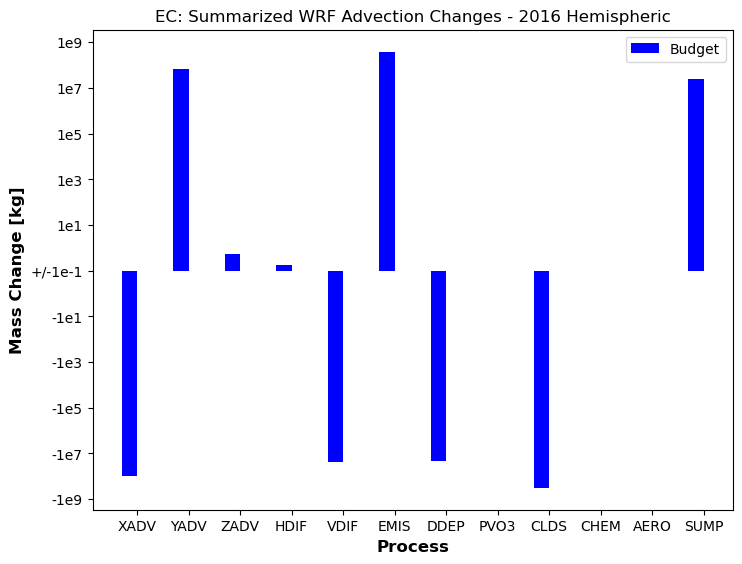

,process,Budget
0,XADV,-9.562687e+07
1,YADV,6.609117e+07
2,ZADV,5.467002e-01
3,HDIF,1.765807e-01
4,VDIF,-2.401127e+07
5,EMIS,3.966858e+08
6,DDEP,-2.042009e+07
7,PVO3,0.000000e+00
8,CLDS,-3.223532e+08
9,CHEM,0.000000e+00


In [9]:
# Output Species
spck = 'EC'

#Processes for Output
outkeys  = ['XADV', 'YADV', 'ZADV', 'HDIF',  'VDIF', 'EMIS', 'DDEP', 'PVO3', \
            'CLDS', 'CHEM', 'COND', 'COAG', 'NPF', 'GROW','SUMP','AER']

# Plotting Parameters
ysmin = 1e-1  # Minimum of the positive and negative sides of the y axis (i.e. cross-over point)
tickstep = 2  # Orders of magnitude between ticks on the y axis
              # The y-axis maximum can be controlled by 'ylarge' below.

for si, spck in enumerate([spck]):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf, spck)

x = ['XADV', 'YADV', 'ZADV', 'HDIF','VDIF', 'EMIS', 'DDEP', 'PVO3', 'CLDS', 'CHEM', 'AERO','SUMP']
z2 = spc_bdf.loc[:, x].sum().to_numpy()

# Create Log Axis
A2 = np.copy(z2)
logmin = np.log10(ysmin)
A2[ z2 > 0 ] = np.log10(A2[ z2 > 0].clip(ysmin)) - logmin
A2[ z2 < 0 ] = -1 * (np.log10(abs(A2 [ z2 < 0 ]).clip(ysmin)) - logmin)

# Make new tick marks
A = A2 #np.concatenate((A1,A2))
z = z2 #np.concatenate((z1,z2))
tick_mks = list(range(-int(np.ceil(abs(A).max())),0,tickstep)) + [0] + list(range(tickstep, int(np.ceil(abs(A).max()))+1,tickstep ))
ylarge = int(np.ceil(np.log10(np.max(abs(z)))))
yfuzzy = int(logmin)
tick_labs_exp = list(range(ylarge,yfuzzy-1,-tickstep)) + list(range(yfuzzy+tickstep,ylarge+1,tickstep))
neglen = len(list(range(ylarge,yfuzzy-1,-tickstep)))-1
tick_labs = ['1e'+str(x) for x in tick_labs_exp]
tick_labs[ 0:neglen ] = ['-'+x for x in tick_labs[0:neglen]]
tick_labs[ neglen ] = '+/-'+ tick_labs[neglen]

# Plot Data
fig = plt.figure()
bar_width = 0.3
X = np.arange(len(A2))
ax = fig.add_axes([0,0,1,1])
ax.bar(X, A2, bar_width, color='b',label='Budget')
#ax.bar(X,A1, bar_width, color='k',label='Process Analysis')
#ax.bar(X+bar_width, A2, bar_width, color='b',label='Budget')
ax.set_xticks(X + bar_width/2)
ax.set_xticklabels(x)
ax.set_xlabel('Process',fontweight='bold',fontsize='large')
ax.set_ylabel('Mass Change [kg]',fontweight='bold',fontsize='large')
ax.set_yticks(tick_mks)
ax.set_yticklabels(tick_labs)
ax.set_title(spck + ': Summarized WRF Advection Changes - 2016 Hemispheric')
ax.legend()
plt.show()

pd.DataFrame(data={'process':x, 'Budget':z2})

## Make a more Complex Plot with Day/Night Classification

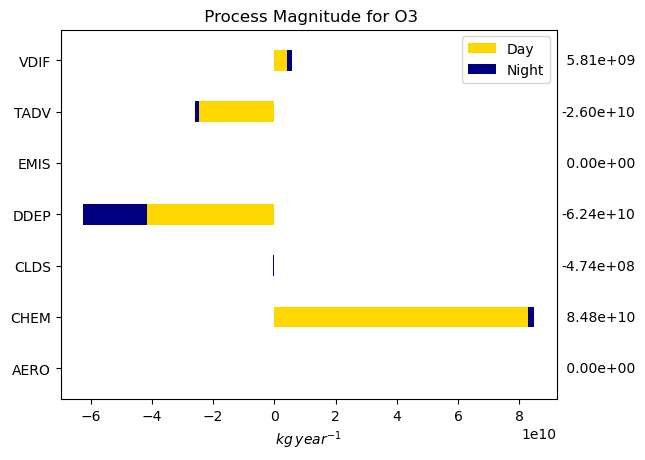

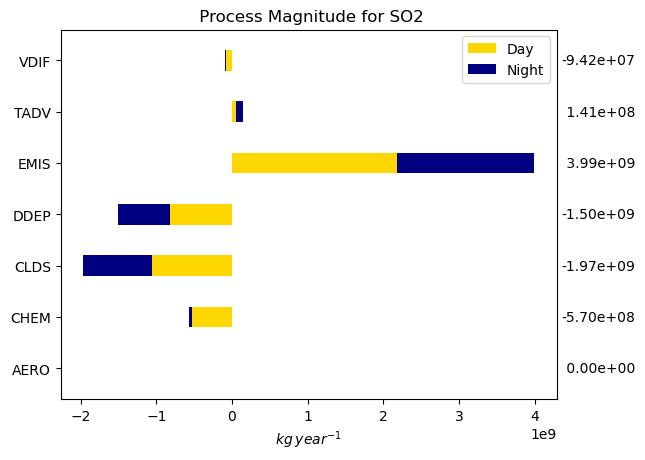

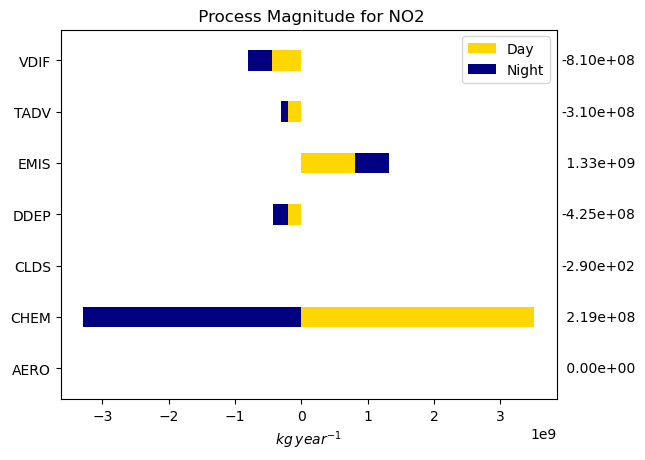

In [10]:
outkeys  = ['VDIF', 'TADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AERO']
frmt = "{:11}"*len(outkeys)
outkeysr = outkeys[::-1]
season_time = ['DayWin','NightWin','DaySpr','NightSpr','DaySum','NightSum','DayAut','NightAut']
spec = ['O3','SO2','NO2']
legend_elements = [Patch(facecolor='gold', label='Day'),
                   Patch(facecolor='navy', label='Night')]

for si, spck in enumerate(spec):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf, spck)
    
    annual_day1 = spc_bdf.loc[day, outkeys].sum()[::-1]
    annual_ngt1 = spc_bdf.loc[night, outkeys].sum()[::-1]

    ind = np.arange(len(outkeys))
    width = 0.4
    
    f1, sax = plt.subplots(1,1)
    
    for i in range(len(outkeys)):
        p1 = plt.barh( ind[i]+width, annual_day1[i], width, color='gold' )
        if annual_day1[i] * annual_ngt1[i] >= 0:
            p2 = plt.barh( ind[i]+width, annual_ngt1[i], width, left = annual_day1[i],color='navy',label='Night' )
        else:
            p2 = plt.barh( ind[i]+width, annual_ngt1[i], width, left = 0,color='navy',label='Night' )

    ax = plt.gca()
    ax.set(yticks=ind + width, yticklabels=outkeysr, ylim=[2*width - 1, len(outkeysr)],xlabel='$kg \: year^{-1}$')
    ax.legend(handles=legend_elements)
    plt.title( ' Process Magnitude for ' + spck)

    # Add total and maximum season-time-of-day
    x = ax.get_xlim()
    annual = annual_day1 + annual_ngt1
    [ ax.text(x[1]+(x[1]-x[0])/100,ind[im]+width-width/5,'%9.2e' % annual[im]) for im in np.arange(len(outkeys))]

    plt.savefig('/shared/build/openmpi_gcc/CMAQ_v54+/data/budget_tool_figs/Fig1_' + spck + '.png', bbox_inches='tight')

## Add Seasonal Classification
(only available if Annual Data Are Provided)

### Set Up Seasonal Masks

In [11]:
# Now create season masks
winter = np.array([ dtarray[i].month == 1 or dtarray[i].month ==  2 or dtarray[i].month == 12 for i in range( len( dtarray)-1) ])
spring = np.array([ dtarray[i].month == 3 or dtarray[i].month ==  4 or dtarray[i].month ==  5 for i in range( len( dtarray)-1) ])
summer = np.array([ dtarray[i].month == 6 or dtarray[i].month ==  7 or dtarray[i].month ==  8 for i in range( len( dtarray)-1) ])
autumn = np.array([ dtarray[i].month == 9 or dtarray[i].month == 10 or dtarray[i].month == 11 for i in range( len( dtarray)-1) ])

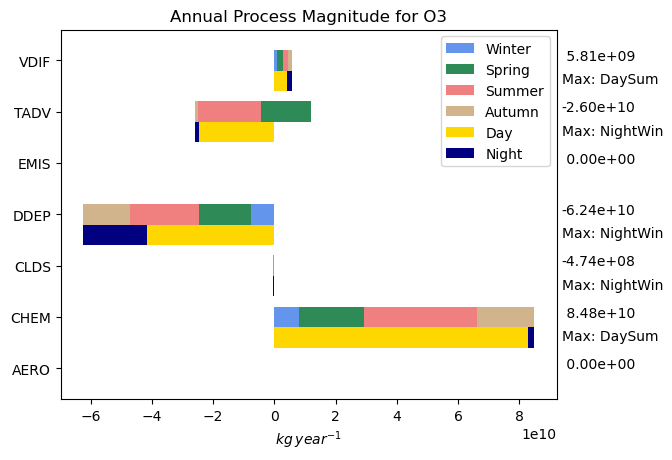

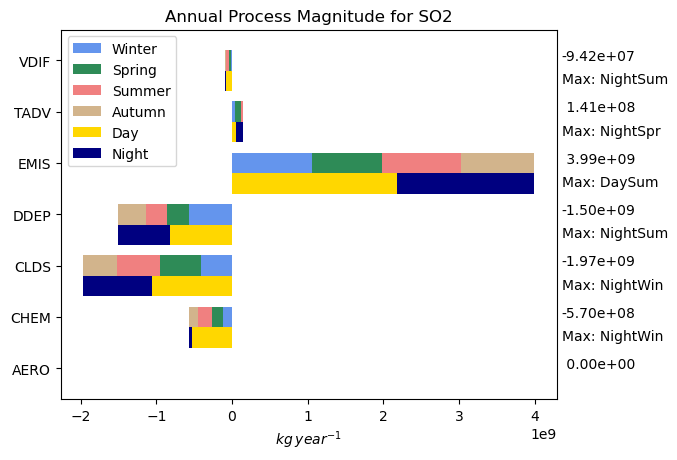

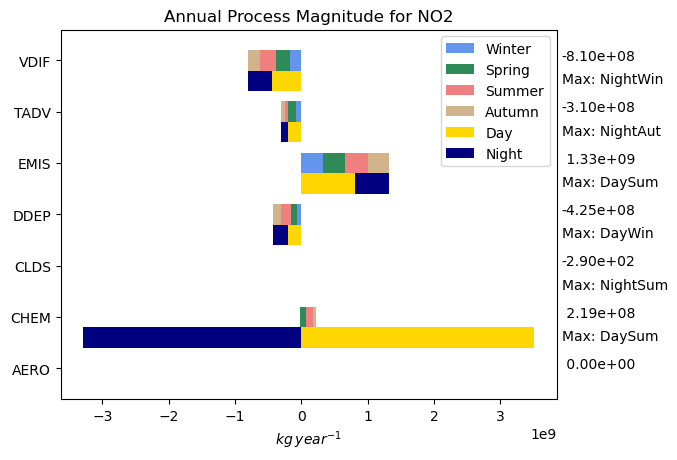

In [12]:
outkeys  = ['VDIF', 'TADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AERO']
frmt = "{:11}"*len(outkeys)
outkeysr = outkeys[::-1]
season_time = ['DayWin','NightWin','DaySpr','NightSpr','DaySum','NightSum','DayAut','NightAut']
spec = ['O3','SO2','NO2']
legend_elements = [Patch(facecolor='cornflowerblue', label='Winter'),
                   Patch(facecolor='seagreen', label='Spring'),
                   Patch(facecolor='lightcoral', label='Summer'),
                   Patch(facecolor='tan', label='Autumn'),
                   Patch(facecolor='gold', label='Day'),
                   Patch(facecolor='navy', label='Night')]

for si, spck in enumerate(spec):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf,spck)
    
    winter_day = spc_bdf.loc[winter & day, outkeys].sum()[::-1]
    winter_ngt = spc_bdf.loc[winter & night, outkeys].sum()[::-1]
    winter_all = winter_day + winter_ngt
    spring_day = spc_bdf.loc[spring & day, outkeys].sum()[::-1]
    spring_ngt = spc_bdf.loc[spring & night, outkeys].sum()[::-1]
    spring_all = spring_day + spring_ngt
    summer_day = spc_bdf.loc[summer & day, outkeys].sum()[::-1]
    summer_ngt = spc_bdf.loc[summer & night, outkeys].sum()[::-1]
    summer_all = summer_day + summer_ngt
    autumn_day = spc_bdf.loc[autumn & day, outkeys].sum()[::-1]
    autumn_ngt = spc_bdf.loc[autumn & night, outkeys].sum()[::-1]
    autumn_all = autumn_day + autumn_ngt
    
    annual_day = spc_bdf.loc[day, outkeys].sum()[::-1]
    annual_ngt = spc_bdf.loc[night, outkeys].sum()[::-1]
    
    ind = np.arange(len(outkeys))
    width = 0.4
    
    f1, sax = plt.subplots(1,1)
    
    p1 = plt.barh( ind+width, winter_all, width, color='cornflowerblue',label='Winter' )
    p2 = plt.barh( ind+width, spring_all, width, left = winter_all, color='seagreen',label='Spring' )
    p3 = plt.barh( ind+width, summer_all, width, left = winter_all+spring_all, color='lightcoral',label='Summer' )
    p4 = plt.barh( ind+width, autumn_all, width, left = winter_all+spring_all+summer_all, color='tan',label='Autumn' )
    
    for i in range(len(outkeys)):
        p5 = plt.barh( ind[i], annual_day[i], width, color='gold', label='Day' )
        if annual_day[i] * annual_ngt[i] >= 0:
            p6 = plt.barh( ind[i], annual_ngt[i], width, left = annual_day[i],color='navy',label='Night' )
        else:
            p6 = plt.barh( ind[i], annual_ngt[i], width, left = 0,color='navy',label='Night' )
            
    ax = plt.gca()
    ax.set(yticks=ind + width, yticklabels=outkeysr, ylim=[2*width - 1, len(outkeysr)],xlabel='$kg \: year^{-1}$')
    ax.legend(handles=legend_elements)
    plt.title('Annual Process Magnitude for '+ spck)
    
    # Add total and maximum season-time-of-day
    x = ax.get_xlim()
    annual = annual_day + annual_ngt
    [ ax.text(x[1]+(x[1]-x[0])/100,ind[im]+width,'%9.2e' % annual[im]) for im in np.arange(len(outkeys))]
    for im in range(len(outkeys)):
        A = [winter_day[im], winter_ngt[im], spring_day[im], spring_ngt[im], summer_day[im], summer_ngt[im], autumn_day[im], autumn_ngt[im]]
        if abs(annual[im]) > 1.0:
            ax.text(x[1]+(x[1]-x[0])/100,ind[im]-0.05, 'Max: ' + season_time[A.index(max(A))] )
        
    plt.savefig('/shared/build/openmpi_gcc/CMAQ_v54+/data/2016_CONUS/budget_tool_figs/Fig1_' + spck + '.png', bbox_inches='tight')

## Make Tables of Seasonal and Day/Night Classifications

In [12]:
outkeys  = ['VDIF', 'ADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AER', 'SUMP']
frmt = "{:11}"*len(outkeys)

for si, spck in enumerate(['HNO3','O3', 'EC', 'ASO4J','ASO4K','ANO3J','ANH4J','ASEACAT','ASVPO1J','NUMATKN']):
    ti = si + 1
    spc_bdf = get_spc_bdf(spck)

    pd.options.display.float_format = '{:.2e}'.format
    print(f'\nTable {ti}: {spck}\n----------------------------')
    print('Process:       ', frmt.format(*outkeys))
    print('Winter(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[winter & day, outkeys].sum()[:]] )
    print('Winter(Night):', *['%9.2e ' % id for id in spc_bdf.loc[winter & night, outkeys].sum()[:]] )
    print('Winter(Total):', *['%9.2e ' % id for id in spc_bdf.loc[winter, outkeys].sum()[:]] )
    
    print('Spring(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[spring & day, outkeys].sum()[:]] )
    print('Spring(Night):', *['%9.2e ' % id for id in spc_bdf.loc[spring & night, outkeys].sum()[:]] )
    print('Spring(Total):', *['%9.2e ' % id for id in spc_bdf.loc[spring, outkeys].sum()[:]] )
    
    print('Summer(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[summer & day, outkeys].sum()[:]] )
    print('Summer(Night):', *['%9.2e ' % id for id in spc_bdf.loc[summer & night, outkeys].sum()[:]] )
    print('Summer(Total):', *['%9.2e ' % id for id in spc_bdf.loc[summer, outkeys].sum()[:]] )
    
    print('Autumn(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[autumn & day, outkeys].sum()[:]] )
    print('Autumn(Night):', *['%9.2e ' % id for id in spc_bdf.loc[autumn & night, outkeys].sum()[:]] )
    print('Autumn(Total):', *['%9.2e ' % id for id in spc_bdf.loc[autumn, outkeys].sum()[:]] )
    
    print('Total(Day):   ', *['%9.2e ' % id for id in spc_bdf.loc[day, outkeys].sum()[:]])
    print('Total(Night): ', *['%9.2e ' % id for id in spc_bdf.loc[night, outkeys].sum()[:]])
    print('Total:        ', *['%9.2e ' % id for id in spc_bdf.loc[:, outkeys].sum()[:]])
    print('----------------------------\n* ADV=advection; DIF=HDIF+VDIF; AER=COND+COAG+NPF+GROW; SUMP=ALL including PVO3')

TypeError: get_spc_bdf() missing 1 required positional argument: 'spck'